# Generalization Analysis

This notebook evaluates the full pipeline (C6) and the smartphone deployment model (C7) under all four validation strategies, compares sensor placements, performs a sensitivity analysis of the preprocessing thresholds, and exports the deployment model.

In [1]:
# Setup: mount Drive and import the shared Component 4 pipeline (MyDrive/PVS_Code/c4_pipeline.py)
import os, sys, importlib
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

CODE_DIR = os.path.join(os.environ.get('C4_DRIVE', '/content/drive/MyDrive'), 'PVS_Code')
assert os.path.exists(os.path.join(CODE_DIR, 'c4_pipeline.py')), \
    'Upload c4_pipeline.py to MyDrive/PVS_Code/ before running this notebook.'
sys.path.insert(0, CODE_DIR)
import c4_pipeline as c4
importlib.reload(c4)
c4.ensure_dirs()
c4.check_setup();

Mounted at /content/drive
Drive folder      : /content/drive/MyDrive
Synced PVS1 found : True
Processed folder  : /content/drive/MyDrive/PVS_Processed True
Feature folder    : /content/drive/MyDrive/PVS_Feature_Datasets_v2 True
Results folder    : /content/drive/MyDrive/PVS_Model_Results_v2 True


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 180)
plt.rcParams['figure.dpi'] = 110
CL = c4.CLASSES
COLORS = {'good': 'tab:green', 'regular': 'goldenrod', 'bad': 'tab:red'}

In [3]:
data = c4.load_data()
CONFIGS = c4.ablation_configs()
FINAL = {k: CONFIGS[k] for k in ['C6 + Stable selection (FULL)', 'C7 Deployment (phone)']}
MODELS = ('SVM', 'RF', 'XGB')

## 1. Final evaluation under all validation strategies

In [ ]:
final, CMS, PRED = [], {}, []
for name, cfg in FINAL.items():
    r, cm, p = c4.run(data, name, cfg, ['Random', 'LORO', 'LOVO', 'LOVO+LORO'], MODELS, keep_predictions=True)
    final.append(r); CMS.update(cm); PRED.append(p[p.split == 'LOVO'])
final = pd.concat(final, ignore_index=True)
PRED = pd.concat(PRED, ignore_index=True)
final.to_csv(os.path.join(c4.RESULTS_DIR, 'final_results.csv'), index=False)
PRED.to_parquet(os.path.join(c4.RESULTS_DIR, 'lovo_out_of_fold_predictions.parquet'), index=False)

summary = final.groupby(['config', 'model', 'split'])['macro_f1'].agg(['mean', 'std']).unstack('split').round(3)
display(summary)
display(c4.degradation_table(final))

  C6 + Stable selection (FULL)   Random    random 80/20             SVM=0.883, RF=0.883, XGB=0.897  (22s)
  C6 + Stable selection (FULL)   LORO      test=route1              SVM=0.788, RF=0.785, XGB=0.806  (17s)
  C6 + Stable selection (FULL)   LORO      test=route2              SVM=0.820, RF=0.748, XGB=0.818  (16s)
  C6 + Stable selection (FULL)   LORO      test=route3              SVM=0.715, RF=0.732, XGB=0.721  (18s)
  C6 + Stable selection (FULL)   LOVO      test=Fiat Bravo          SVM=0.809, RF=0.779, XGB=0.821  (18s)
  C6 + Stable selection (FULL)   LOVO      test=Fiat Palio          SVM=0.836, RF=0.848, XGB=0.847  (19s)
  C6 + Stable selection (FULL)   LOVO      test=VW Saveiro          SVM=0.836, RF=0.853, XGB=0.848  (17s)
  C6 + Stable selection (FULL)   LOVO+LORO test=Fiat Bravo/route1   SVM=0.805, RF=0.772, XGB=0.813  (12s)
  C6 + Stable selection (FULL)   LOVO+LORO test=Fiat Bravo/route2   SVM=0.739, RF=0.645, XGB=0.708  (13s)
  C6 + Stable selection (FULL)   LOVO+LORO tes

mean                            std                        
split                                LORO   LOVO LOVO+LORO Random   LORO   LOVO LOVO+LORO Random
config                       model                                                              
C6 + Stable selection (FULL) RF     0.755  0.826     0.745  0.883  0.027  0.041     0.060    NaN
                             SVM    0.774  0.827     0.760  0.883  0.054  0.016     0.070    NaN
                             XGB    0.782  0.839     0.777  0.897  0.053  0.016     0.080    NaN
C7 Deployment (phone)        RF     0.719  0.819     0.703  0.865  0.053  0.036     0.082    NaN
                             SVM    0.744  0.799     0.712  0.868  0.028  0.023     0.064    NaN
                             XGB    0.772  0.828     0.759  0.889  0.021  0.008     0.084    NaN

split                                LORO   LOVO  LOVO+LORO  Random  LOVO_std  Degradation
config                       model                                                        
C6 + Stable selection (FULL) RF     0.755  0.826      0.745   0.883     0.041        0.057
                             SVM    0.774  0.827      0.760   0.883     0.016        0.056
                             XGB    0.782  0.839      0.777   0.897     0.016        0.058
C7 Deployment (phone)        RF     0.719  0.819      0.703   0.865     0.036        0.045
                             SVM    0.744  0.799      0.712   0.868     0.023        0.070
                             XGB    0.772  0.828      0.759   0.889     0.008        0.061

In [ ]:
print('Per-fold LOVO results (the fold "test=Fiat Palio" corresponds to the earlier PVS1-6 -> PVS7-9 experiment):')
display(final[final.split == 'LOVO'][['config', 'model', 'fold', 'n_test', 'accuracy', 'macro_f1',
                                       'f1_good', 'f1_regular', 'f1_bad', 'recall_bad']].round(3))

Per-fold LOVO results (the fold "test=Fiat Palio" corresponds to the earlier PVS1-6 -> PVS7-9 experiment):


,config,model,fold,n_test,accuracy,macro_f1,f1_good,f1_regular,f1_bad,recall_bad
12,C6 + Stable selection (FULL),SVM,test=Fiat Bravo,2784,0.843,0.809,0.982,0.839,0.606,0.521
13,C6 + Stable selection (FULL),RF,test=Fiat Bravo,2784,0.837,0.779,0.989,0.842,0.506,0.369
14,C6 + Stable selection (FULL),XGB,test=Fiat Bravo,2784,0.859,0.821,0.992,0.859,0.611,0.494
15,C6 + Stable selection (FULL),SVM,test=Fiat Palio,2644,0.860,0.836,0.990,0.820,0.699,0.810
16,C6 + Stable selection (FULL),RF,test=Fiat Palio,2644,0.878,0.848,0.989,0.855,0.699,0.692
17,C6 + Stable selection (FULL),XGB,test=Fiat Palio,2644,0.871,0.847,0.989,0.839,0.713,0.788
18,C6 + Stable selection (FULL),SVM,test=VW Saveiro,2851,0.871,0.836,0.989,0.850,0.671,0.727
19,C6 + Stable selection (FULL),RF,test=VW Saveiro,2851,0.890,0.853,0.992,0.875,0.691,0.674
20,C6 + Stable selection (FULL),XGB,test=VW Saveiro,2851,0.881,0.848,0.993,0.861,0.689,0.725
60,C7 Deployment (phone),SVM,test=Fiat Bravo,2784,0.855,0.825,0.983,0.850,0.641,0.558


In [ ]:
FULL = 'C6 + Stable selection (FULL)'
best = final[(final.config == FULL) & (final.split == 'LOVO')].groupby('model')['macro_f1'].mean().idxmax()
print('Best generalising model (mean LOVO macro-F1):', best)
folds = [f for f, _, _ in data.splits()['LOVO']]
fig, axes = plt.subplots(1, len(folds), figsize=(4.2 * len(folds), 3.6))
for ax, f in zip(np.atleast_1d(axes), folds):
    cm = CMS.get((FULL, 'LOVO', f, best))
    if cm is None: continue
    cmn = cm / cm.sum(1, keepdims=True).clip(min=1)
    ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f'{cmn[i, j]:.2f}\n({cm[i, j]})', ha='center', va='center', fontsize=8)
    ax.set_xticks(range(3), CL); ax.set_yticks(range(3), CL)
    ax.set_xlabel('predicted'); ax.set_ylabel('true'); ax.set_title(f'{best} – {f}', fontsize=9)
plt.tight_layout(); plt.savefig(os.path.join(c4.RESULTS_DIR, 'lovo_confusion_matrices.png'), dpi=150); plt.show()

## 2. Sensor placement comparison
The full pipeline (C6 handling) with different sensor sets, under LOVO. This answers whether combining sensors helps, and how much is lost when only a phone-like dashboard sensor is available.

In [ ]:
base = CONFIGS[FULL]
placement_sets = {
    'dashboard (L+R)': c4.DASHBOARD,
    'above suspension (L+R)': ['left_above_suspension', 'right_above_suspension'],
    'below suspension (L+R)': ['left_below_suspension', 'right_below_suspension'],
    'all six sensors': c4.SENSORS,
    'left dashboard only': ['left_dashboard'],
    'left dashboard, invariant only (C7)': ['left_dashboard'],
}
pl = []
for name, sensors in placement_sets.items():
    ch = c4.ROBUST_CH if 'invariant' in name else c4.PROC_CH
    r, _ = c4.run(data, name, {**base, 'sensors': sensors, 'channels': ch}, ['Random', 'LOVO'], MODELS, verbose=False)
    pl.append(r); print('done:', name)
pl = pd.concat(pl, ignore_index=True)
PL = c4.degradation_table(pl, order=list(placement_sets))
display(PL)
PL.to_csv(os.path.join(c4.RESULTS_DIR, 'placement_comparison.csv'))

done: dashboard (L+R)
done: above suspension (L+R)
done: below suspension (L+R)
done: all six sensors
done: left dashboard only
done: left dashboard, invariant only (C7)


split                                       LOVO  Random  LOVO_std  Degradation
config                              model                                      
dashboard (L+R)                     RF     0.826   0.883     0.041        0.057
                                    SVM    0.827   0.883     0.016        0.056
                                    XGB    0.839   0.897     0.016        0.058
above suspension (L+R)              RF     0.814   0.871     0.038        0.057
                                    SVM    0.823   0.872     0.004        0.049
                                    XGB    0.836   0.884     0.010        0.048
below suspension (L+R)              RF     0.801   0.868     0.052        0.067
                                    SVM    0.802   0.878     0.015        0.076
                                    XGB    0.813   0.892     0.006        0.079
all six sensors                     RF     0.753   0.779     0.030        0.026
                                    SVM    0.775   0.825     0.035        0.050
                                    XGB    0.761   0.804     0.028        0.043
left dashboard only                 RF     0.831   0.885     0.038        0.054
                                    SVM    0.823   0.881     0.020        0.058
                                    XGB    0.843   0.888     0.014        0.045
left dashboard, invariant only (C7) RF     0.819   0.865     0.036        0.045
                                    SVM    0.799   0.868     0.023        0.070
                                    XGB    0.828   0.889     0.008        0.061

## 3. Sensitivity analysis of preprocessing thresholds
Each parameter is varied while all others keep their default values (full pipeline, LOVO, best model). Note that thresholds that change the evaluation set (purity, minimum speed) also change the test windows.

,parameter,value,macro_f1,std,test windows
0,"manoeuvre thresholds (lat, long)","1.0, 0.7",0.842,0.016,7015
1,"manoeuvre thresholds (lat, long)","1.5, 1.0",0.839,0.016,8279
2,"manoeuvre thresholds (lat, long)","2.0, 1.5",0.841,0.021,9029
3,"manoeuvre thresholds (lat, long)",off,0.838,0.021,9268
4,min label purity,0.6,0.826,0.014,8632
5,min label purity,0.8,0.839,0.016,8279
6,min label purity,0.9,0.852,0.019,8093
7,min label purity,1.0,0.855,0.027,7889
8,min speed (m/s),0.5,0.834,0.020,8303
9,min speed (m/s),1.0,0.839,0.016,8279


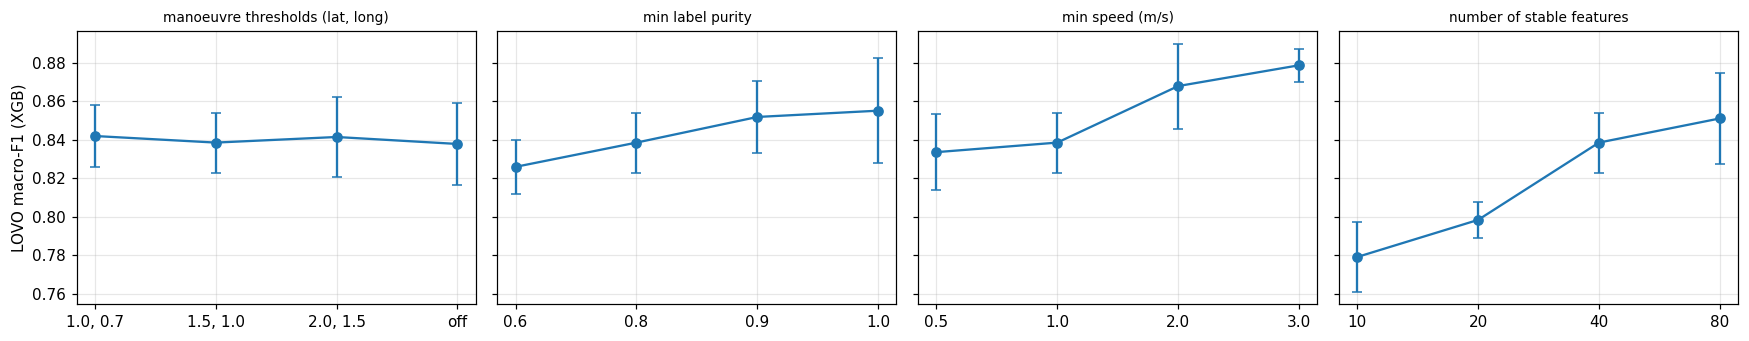

In [ ]:
SENS_MODEL = best
sens = []
def sens_run(param, value, **th):
    data.set_thresholds(**th)
    r, _ = c4.run(data, FULL, CONFIGS[FULL], ['LOVO'], (SENS_MODEL,), verbose=False)
    sens.append({'parameter': param, 'value': value, 'macro_f1': r.macro_f1.mean(), 'std': r.macro_f1.std(),
                 'test windows': int(r.n_test.sum())})

for lat, lon in [(1.0, 0.7), (1.5, 1.0), (2.0, 1.5), (99, 99)]:
    sens_run('manoeuvre thresholds (lat, long)', f'{lat}, {lon}' if lat < 99 else 'off', lat_acc_max=lat, long_acc_max=lon)
for p in [0.6, 0.8, 0.9, 1.0]:
    sens_run('min label purity', p, min_purity=p)
for s in [0.5, 1.0, 2.0, 3.0]:
    sens_run('min speed (m/s)', s, min_speed=s)
data.set_thresholds()
for k in [10, 20, 40, 80]:
    r, _ = c4.run(data, FULL, {**CONFIGS[FULL], 'k': k}, ['LOVO'], (SENS_MODEL,), verbose=False)
    sens.append({'parameter': 'number of stable features', 'value': k, 'macro_f1': r.macro_f1.mean(),
                 'std': r.macro_f1.std(), 'test windows': int(r.n_test.sum())})
SENS = pd.DataFrame(sens)
display(SENS.round(3))
SENS.to_csv(os.path.join(c4.RESULTS_DIR, 'sensitivity_analysis.csv'), index=False)

params = SENS.parameter.unique()
fig, axes = plt.subplots(1, len(params), figsize=(4 * len(params), 3.2), sharey=True)
for ax, p in zip(axes, params):
    s = SENS[SENS.parameter == p]
    ax.errorbar(s.value.astype(str), s.macro_f1, yerr=s['std'], marker='o', capsize=3)
    ax.set_title(p, fontsize=9); ax.grid(alpha=.3)
axes[0].set_ylabel(f'LOVO macro-F1 ({SENS_MODEL})')
plt.tight_layout(); plt.savefig(os.path.join(c4.RESULTS_DIR, 'sensitivity.png'), dpi=150); plt.show()

## 4. Export of the smartphone deployment model (C7)
The C7 model uses only the four orientation-invariant channels of one dashboard sensor, which can be computed from any smartphone. It is trained on all usable windows and saved together with every parameter the cloud service needs.

In [ ]:
import joblib
DEP = 'C7 Deployment (phone)'
dep_best = final[(final.config == DEP) & (final.split == 'LOVO')].groupby('model')['macro_f1'].mean().idxmax()
tr_all = c4.train_index(data, CONFIGS[DEP], np.ones(len(data.A), bool))
Xd, info = c4.prepare(data, CONFIGS[DEP], tr_all)
model = c4.fit(dep_best, Xd.values[tr_all], data.y[tr_all])
bundle = {'model': model, 'model_name': dep_best, 'features': list(Xd.columns),
          'speed_slopes': info.get('slopes'), 'speed_ref_log': info.get('ref'),
          'config': dict(c4.CFG), 'sensor': c4.CFG['DEPLOY_SENSOR'], 'channels': c4.ROBUST_CH,
          'classes': c4.CLASSES,
          'lovo_macro_f1': float(final[(final.config == DEP) & (final.split == 'LOVO') & (final.model == dep_best)].macro_f1.mean()),
          'notes': 'Per-trip normalisation statistics and the stationary noise profile are computed on each incoming trip.'}
path = os.path.join(c4.RESULTS_DIR, 'c4_deployment_model.joblib')
joblib.dump(bundle, path)
print(f'Saved {dep_best} deployment model ({len(Xd.columns)} features, LOVO macro-F1 {bundle["lovo_macro_f1"]:.3f}) -> {path}')

Saved XGB deployment model (40 features, LOVO macro-F1 0.828) -> /content/drive/MyDrive/PVS_Model_Results_v2/c4_deployment_model.joblib


## 5. Speed-feature ablation
Notebook 02 (Section 10.1) showed that driving speed depends strongly on the road class, mainly because good roads are driven faster. Speed is therefore an easy shortcut for the classifier. The full pipeline (C6) removes the raw speed features and speed-normalises the amplitude features. This experiment tests that decision directly with four variants, under all four validation strategies:

| Variant | Speed normalisation | Raw speed features |
|---|---|---|
| C6 FULL (reference) | yes | removed |
| C6 + raw speed features | yes | added to the 40 selected features |
| C6 without speed normalisation | no | removed |
| Speed only | – | the only features (`speed_mean`, `speed_std`) |

If speed were a reliable road-surface cue, adding it would help on unseen routes (LORO). If it is a route- or driver-specific shortcut, it can help on the random split but should help less, or hurt, when the route or vehicle-driver is new. The C6 reference values are read from `final_results.csv` (Section 1), so they are identical to the main results.

In [4]:
# Speed-feature ablation: C6 variants that differ only in how speed is used
FULL = 'C6 + Stable selection (FULL)'
SPEED_COLS = c4.SPEED_COLS
_prepare_c6 = c4.prepare                      # original preparation function of the pipeline

def prepare_speed_variant(data, cfg, tr):
    """'keep': C6 + raw speed features; 'none': C6 without speed normalisation; 'only': speed features only."""
    mode = cfg.get('speed', 'default')
    if mode == 'default':
        return _prepare_c6(data, cfg, tr)
    if mode == 'only':
        return data.F_PROC[SPEED_COLS].astype(np.float32), {}
    X = c4.config_columns(data, cfg)
    speed = X[SPEED_COLS].copy()
    X = X.drop(columns=SPEED_COLS)               # speed never enters feature selection
    info = {}
    if mode == 'keep':                           # same speed normalisation as C6
        slopes, ref = c4.fit_speed_slopes(data, X, tr)
        X = c4.apply_speed_norm(data, X, slopes, ref)
    if cfg['trip']:
        X = c4.trip_normalize(data, X)
    if cfg['sel']:
        info['selected'] = c4.stable_select(data, X, tr, cfg.get('k'))
        X = X[info['selected']]
    if mode == 'keep':
        X = pd.concat([X, speed.astype(np.float32)], axis=1)
    return X, info

SPEED_VARIANTS = {
    'C6 + raw speed features':        {**CONFIGS[FULL], 'speed': 'keep'},
    'C6 without speed normalisation': {**CONFIGS[FULL], 'speed': 'none'},
    'Speed only':                     {**CONFIGS[FULL], 'speed': 'only'},
}
SPLITS = ['Random', 'LORO', 'LOVO', 'LOVO+LORO']
c4.prepare = prepare_speed_variant            # c4.run() uses c4.prepare internally
try:
    speed_res = [c4.run(data, name, cfg, SPLITS, MODELS)[0] for name, cfg in SPEED_VARIANTS.items()]
finally:
    c4.prepare = _prepare_c6                  # always restore the original function

ref = pd.read_csv(os.path.join(c4.RESULTS_DIR, 'final_results.csv'))
ref = ref[ref.config == FULL].assign(config='C6 FULL (reference)')
speed_ab = pd.concat([ref] + speed_res, ignore_index=True)
speed_ab.to_csv(os.path.join(c4.RESULTS_DIR, 'speed_ablation.csv'), index=False)

  C6 + raw speed features        Random    random 80/20             SVM=0.903, RF=0.916, XGB=0.930  (19s)
  C6 + raw speed features        LORO      test=route1              SVM=0.843, RF=0.841, XGB=0.858  (19s)
  C6 + raw speed features        LORO      test=route2              SVM=0.877, RF=0.828, XGB=0.910  (16s)
  C6 + raw speed features        LORO      test=route3              SVM=0.790, RF=0.777, XGB=0.786  (17s)
  C6 + raw speed features        LOVO      test=Fiat Bravo          SVM=0.859, RF=0.857, XGB=0.898  (16s)
  C6 + raw speed features        LOVO      test=Fiat Palio          SVM=0.911, RF=0.903, XGB=0.907  (16s)
  C6 + raw speed features        LOVO      test=VW Saveiro          SVM=0.873, RF=0.886, XGB=0.899  (16s)
  C6 + raw speed features        LOVO+LORO test=Fiat Bravo/route1   SVM=0.832, RF=0.814, XGB=0.842  (12s)
  C6 + raw speed features        LOVO+LORO test=Fiat Bravo/route2   SVM=0.822, RF=0.718, XGB=0.823  (12s)
  C6 + raw speed features        LOVO+LORO tes

Mean macro-F1 per variant, model and validation strategy


split                                 Random   LORO   LOVO  LOVO+LORO  Random - LORO  Random - LOVO
config                         model                                                               
C6 FULL (reference)            RF      0.883  0.755  0.826      0.745          0.128          0.057
                               SVM     0.883  0.774  0.827      0.760          0.109          0.056
                               XGB     0.897  0.782  0.839      0.777          0.115          0.058
C6 + raw speed features        RF      0.916  0.815  0.882      0.800          0.101          0.034
                               SVM     0.903  0.837  0.881      0.801          0.066          0.022
                               XGB     0.930  0.851  0.901      0.835          0.079          0.029
C6 without speed normalisation RF      0.820  0.658  0.726      0.649          0.161          0.093
                               SVM     0.837  0.684  0.729      0.684          0.152          0.107
                               XGB     0.854  0.681  0.746      0.681          0.173          0.109
Speed only                     RF      0.781  0.712  0.784      0.703          0.068         -0.003
                               SVM     0.793  0.749  0.787      0.740          0.043          0.006
                               XGB     0.795  0.733  0.780      0.721          0.062          0.015

Change compared with C6 FULL (positive = better than C6)


split                                 Random   LORO   LOVO  LOVO+LORO
config                         model                                 
C6 + raw speed features        RF      0.033  0.060  0.056      0.054
                               SVM     0.020  0.062  0.054      0.042
                               XGB     0.033  0.069  0.063      0.058
C6 without speed normalisation RF     -0.064 -0.097 -0.100     -0.096
                               SVM    -0.046 -0.090 -0.098     -0.076
                               XGB    -0.042 -0.101 -0.093     -0.096
Speed only                     RF     -0.103 -0.043 -0.042     -0.042
                               SVM    -0.090 -0.025 -0.041     -0.020
                               XGB    -0.102 -0.049 -0.058     -0.056

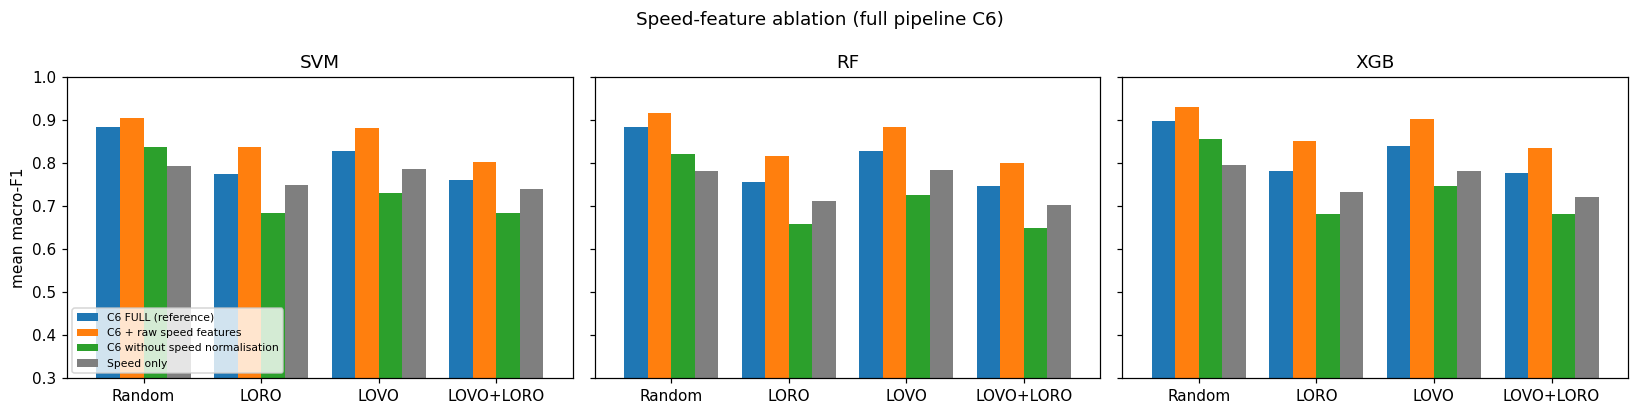

In [5]:
ORDER = ['C6 FULL (reference)', 'C6 + raw speed features', 'C6 without speed normalisation', 'Speed only']
tab = speed_ab.groupby(['config', 'model', 'split'])['macro_f1'].mean().unstack('split')[SPLITS]
tab = tab.reindex(ORDER, level=0)
tab['Random - LORO'] = tab['Random'] - tab['LORO']
tab['Random - LOVO'] = tab['Random'] - tab['LOVO']
print('Mean macro-F1 per variant, model and validation strategy')
display(tab.round(3))

delta = tab[SPLITS].sub(tab.loc['C6 FULL (reference)'][SPLITS], level='model').drop('C6 FULL (reference)', level=0)
print('Change compared with C6 FULL (positive = better than C6)')
display(delta.round(3))

fig, axes = plt.subplots(1, len(MODELS), figsize=(15, 3.8), sharey=True)
for ax, m in zip(axes, MODELS):
    tab.xs(m, level='model')[SPLITS].T.plot(kind='bar', ax=ax, rot=0, width=.8,
                                            color=['tab:blue', 'tab:orange', 'tab:green', 'tab:grey'])
    ax.set_title(m); ax.set_ylim(0.3, 1); ax.set_xlabel('')
    ax.legend(fontsize=7, loc='lower left') if m == MODELS[0] else ax.get_legend().remove()
axes[0].set_ylabel('mean macro-F1')
plt.suptitle('Speed-feature ablation (full pipeline C6)'); plt.tight_layout()
plt.savefig(os.path.join(c4.RESULTS_DIR, 'speed_ablation.png'), dpi=150); plt.show()

**Result** (mean macro-F1, XGB; full table above):

| Variant | Random | LORO | LOVO | LOVO+LORO |
|---|---|---|---|---|
| C6 FULL (reference) | 0.897 | 0.782 | 0.839 | 0.777 |
| C6 + raw speed features | 0.930 | 0.851 | 0.901 | 0.835 |
| C6 without speed normalisation | 0.854 | 0.681 | 0.746 | 0.681 |
| Speed only | 0.795 | 0.733 | 0.780 | 0.721 |

* **Speed normalisation is essential.** Without it, macro-F1 drops by about 0.08–0.10 on every unseen-context split for all three models. Vibration amplitude grows with speed, so without normalisation the same road gives different feature values at different speeds and roughness is confused with driving speed. (This variant also drops the log transform that the normalisation applies to amplitude features.)
* **Raw speed is a very strong cue in PVS.** Speed alone reaches 0.78 on an unseen vehicle-driver, and adding it to C6 improves every unseen-context split (LORO, LOVO, LOVO+LORO) by about 0.04–0.07 for all three models. The hypothesis that speed would hurt generalisation is therefore **not** supported by PVS.
* **Why the cue transfers here.** All three drivers drove in the same city and slowed down on bad roads in the same way (Notebook 02, Section 10.1), so leaving one driver or route out does not break the speed–class relation. PVS cannot test a driver with different habits, slow traffic on a good road, or fast driving on a rough road. In those cases a speed-based model would classify the driving situation rather than the road surface.
* **Decision.** C6 (no raw speed) remains the main model, for three reasons. (1) The research question is road-surface assessment that is independent of the vehicle-driver; speed describes how the driver drives, so it is exactly the kind of driver-dependent cue the pipeline is designed to remove. (2) The target deployment is Sri Lankan roads, where congestion often forces low speeds on good roads and buses or three-wheelers may drive fast on rough roads; a speed-based model would misclassify both cases, while C6 relies only on vibration. (3) Speed alone already reaches 0.78, which suggests that much of the +0.06 gain of C6 + raw speed comes from the shared driving behaviour of the three PVS drivers and may not transfer to other drivers or traffic conditions. C6 + raw speed is reported as a context-aware upper bound, and testing it on Sri Lankan smartphone data with congested traffic is future work.


## 6. Findings template
* **Generalisation:** report mean ± std LOVO macro-F1 of the full pipeline and its degradation compared with the random split, and compare with C0 (Notebook 06).
* **Fold differences:** discuss which vehicle-driver is hardest and which classes are confused (usually Regular vs. Bad).
* **Routes:** compare LORO and LOVO+LORO with LOVO to separate the effect of unseen roads from unseen vehicle-drivers.
* **Placement:** state how much performance the phone-like dashboard sensor retains compared with all six sensors.
* **Sensitivity:** state which thresholds the results are robust to.
* **Speed:** report that speed normalisation is essential (Section 5) and that raw speed is excluded by design although it improves PVS scores, because it encodes driving behaviour rather than the road surface.
* **Limitation:** vehicle and driver are confounded; three contexts only; categorical labels (no IRI).